In [1]:
from gbh_model import Model, cmf, spotpy, pd
import plotly.graph_objects as go

In [2]:
model = Model(22222)
p = spotpy.parameter.create_set(model, 'optguess')
model.parameterize(p)
print(cmf.describe(model.project))


cmf.project(1 cells, 1 meteo stations, 2 project nodes)

Project nodes:
    - {gw}:
        - LinearStorageConnection({Layer #4 of cell #0}<->{gw})
    - {runoff}:
        - waterbalance connection({Surface water of cell #0}<->{runoff})

Cells:
    - cell #0(0,0,0):
        - {Canopy}:
            - Intercepted rain({Rainfall from gbh}<->{Canopy})
            - Penman Monteith (canopy) get_evaporation({Canopy}<->{Evaporation of cell #0})
            - Rutter interception({Canopy}<->{Surface water of cell #0})
        - {macropores}:
            - PartitionFluxRoute({Layer #0 of cell #0}<->{macropores})
            - PartitionFluxRoute({macropores}<->{Layer #4 of cell #0})
            - PartitionFluxRoute({macropores}<->{Layer #3 of cell #0})
            - PartitionFluxRoute({macropores}<->{Layer #2 of cell #0})
            - PartitionFluxRoute({macropores}<->{Layer #1 of cell #0})
        - {Layer #0 of cell #0}:
            - simple infiltration({Surface water of cell #0}<->{Layer #0 

In [3]:
%time sim = model.simulation(p, True)
sim_df = model.simulation_to_df(sim)
objf = model.objectivefunction(sim, model.evaluation())
print(f'RMSE40cm={objf[0]:0.3f}, RMSE60cm={objf[1]:0.3f}, '
    f'P={objf[2]:0.3f}, ET={objf[3]:0.3f}, GW={objf[4]:0.3f}, RO={objf[5]:0.3f}')


2020-08-20 00:00 : P=-0.000 ET=0.090 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-21 00:00 : P=-0.000 ET=0.290 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-22 00:00 : P=7.200 ET=0.176 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-23 00:00 : P=-0.000 ET=0.195 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-24 00:00 : P=-0.000 ET=1.049 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-25 00:00 : P=-0.000 ET=0.169 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-26 00:00 : P=-0.000 ET=4.226 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-27 00:00 : P=-0.000 ET=0.441 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-28 00:00 : P=-0.000 ET=0.551 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-29 00:00 : P=-0.000 ET=0.278 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-30 00:00 : P=-0.000 ET=0.000 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-08-31 00:00 : P=-0.000 ET=0.000 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-09-01 00:00 : P=-0.000 ET=0.000 GW=0.000 RO=0.000, LAI=2.88, Kc=0.40
2020-09-02 00:00 : P=-0.000 ET=0.012 GW

In [4]:
objf = model.objectivefunction(sim, model.evaluation())
print(f'RMSE40cm={objf[0]:0.3f}, RMSE60cm={objf[1]:0.3f}, '
    f'P={objf[2]:0.3f}, ET={objf[3]:0.3f}, GW={objf[4]:0.3f}, RO={objf[5]:0.3f}')


RMSE40cm=0.075, RMSE60cm=0.073, P=515.400, ET=395.940, GW=109.103, RO=54.231


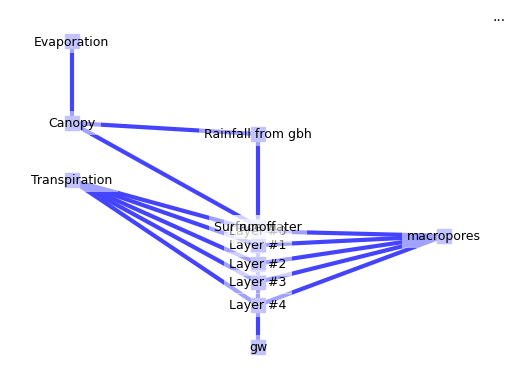

In [5]:
from fluxogram import Fluxogram
from matplotlib.pyplot import show
fg = Fluxogram(model.groundwater, macropores=(+1, -0.1), Rainfall=(0, -19), Transpiration=(-1, -19.5), gw=(0,+0.7))
_=fg.init_plot()
#_=fg.update(model.meteo.T.end)


<Axes: >

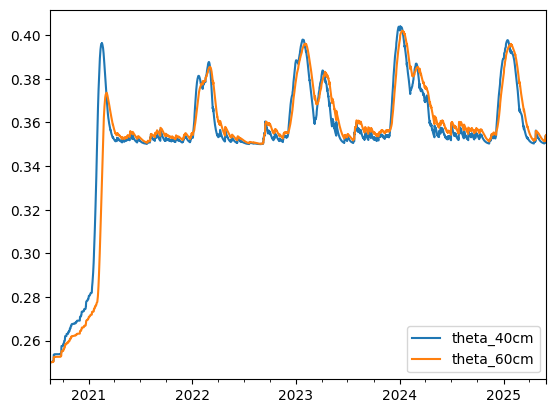

In [6]:

sim_df[sim_df.columns[-2:]].plot()

In [9]:
soilmoisture = pd.read_excel('moisture.xlsx', index_col=0)
import plotly.graph_objects as go
fig = go.Figure()
fig.add_trace(go.Scatter(x=soilmoisture.index, y=soilmoisture[soilmoisture.columns[::2]].mean(1), name='40cm', mode='lines'))
fig.add_trace(go.Scatter(x=soilmoisture.index, y=soilmoisture[soilmoisture.columns[1::2]].mean(1), name='60cm', mode='lines'))


fig.show()
#soilmoisture[soilmoisture.columns[1::2]].mean(1).plot(label='soil moisture 60cm')

In [12]:
pd.to_datetime('2024-01-01') + pd.Timedelta(days=220)

Timestamp('2024-08-08 00:00:00')

In [16]:
Kc = [model.Kc_WinterWeizen(i) for i in range(1, 366)]
fig = go.Figure()
fig.add_trace(go.Scatter(x=list(range(1, 366)), y=Kc, mode='lines', name='Kc Winterweizen'))
fig.update_layout(title='Kc Winterweizen', xaxis_title='Day of Year', yaxis_title='Kc')
fig.show()

In [17]:
model.parameters

[Uniform('soil_capacity', [10, 1000]),
 Uniform('ETV1', [0.1, 0.9]),
 Uniform('ETV0', [0.0, 0.9]),
 Uniform('Sfc', [0.1, 1.0]),
 Uniform('retention_time', [1, 150]),
 Uniform('Ksat', [1, 200]),
 Uniform('infexp', [0.001, 2.0])]